<a href="https://colab.research.google.com/github/yukeshhhh/yukeshhhamypoML/blob/main/Day3_Reggression_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (442, 11)

--- Simple Linear Regression (BMI) ---
Slope: 998.5776891375598
Intercept: 152.00335421448167

--- Multiple Linear Regression (All Features) ---
Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995

--- Polynomial Regression (Degree 2, BMI) ---

--- Multiple Linear Regression Metrics ---
MAE: 42.79409467959994
MSE: 2900.1936284934814
RMSE: 53.85344583676593
R2: 0.4526027629719195

--- Regularized Regression (R2) ---
Ridge R2: 0.454
Lasso R2: 0.456
ElasticNet R2: 0.459

--- Statsmodels OLS Summary ---
                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:             

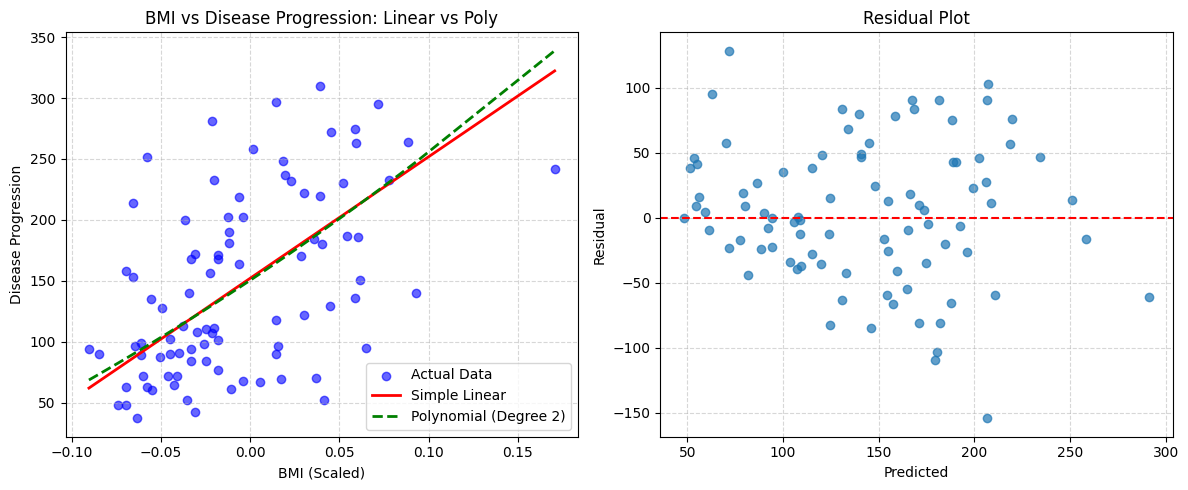

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. Load & Inspect Dataset
dataset = load_diabetes(as_frame=True)
df = dataset.frame
print("Dataset shape:", df.shape)

# 2. Separate Features (X) and Target (y)
X = df.drop(columns=["target"])
y = df["target"]

# 3. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Simple Linear Regression (Using 'bmi')
Xtr = X_train[["bmi"]]
Xte = X_test[["bmi"]]
simple = LinearRegression()
simple.fit(Xtr, y_train)
pred_simple = simple.predict(Xte)

print("\n--- Simple Linear Regression (BMI) ---")
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)

# 5. Multiple Linear Regression (All 10 Features)
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)

print("\n--- Multiple Linear Regression (All Features) ---")
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)

# 6. Polynomial Regression (Degree = 2 on 'bmi')
poly = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly.fit(Xtr, y_train)
poly_pred = poly.predict(Xte)

print("\n--- Polynomial Regression (Degree 2, BMI) ---")

# 7. Model Evaluation Metrics (MAE, MSE, RMSE, R2) for Multiple Linear Regression
mae = mean_absolute_error(y_test, pred_multi)
mse = mean_squared_error(y_test, pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred_multi)

print("\n--- Multiple Linear Regression Metrics ---")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

# 8. Regularized Regression Models (Ridge, Lasso, ElasticNet)
models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}

print("\n--- Regularized Regression (R2) ---")
for name, alg in models.items():
    pipe = make_pipeline(StandardScaler(), alg)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    print(f"{name} R2:", round(r2_score(y_test, p), 3))

# 9. OLS Regression Summary using Statsmodels
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit()
print("\n--- Statsmodels OLS Summary ---")
print(ols.summary())

# 10. Visualization 1: Simple Linear vs Polynomial Fit
order = np.argsort(X_test["bmi"].values)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_test["bmi"], y_test, color="blue", alpha=0.6, label="Actual Data")
plt.plot(Xte.values[order], pred_simple[order], color="red", linewidth=2, label="Simple Linear")
plt.plot(X_test["bmi"].values[order], poly_pred[order], color="green", linestyle="--", linewidth=2, label="Polynomial (Degree 2)")
plt.title("BMI vs Disease Progression: Linear vs Poly")
plt.xlabel("BMI (Scaled)")
plt.ylabel("Disease Progression")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# 11. Visualization 2: Residual Plot
residuals = y_test - pred_multi
plt.subplot(1, 2, 2)
plt.scatter(pred_multi, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()